In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

TEST_WEEKS = 8
DATA_PATH = "../part3_synthetic_data/data/sales.csv"  # при необходимости поправьте путь

In [2]:
df = pd.read_csv(DATA_PATH, parse_dates=["date"])
print(df.shape)
df.info()
df.isna().sum()

(59184, 10)
<class 'pandas.DataFrame'>
RangeIndex: 59184 entries, 0 to 59183
Data columns (total 10 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   date            59184 non-null  datetime64[us]
 1   store_id        59184 non-null  str           
 2   city            59184 non-null  str           
 3   category        59184 non-null  str           
 4   product         59184 non-null  str           
 5   qty             59184 non-null  int64         
 6   price           58711 non-null  float64       
 7   cost            59184 non-null  float64       
 8   promo           59184 non-null  int64         
 9   payment_method  58711 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(2), str(5)
memory usage: 4.5 MB


date                0
store_id            0
city                0
category            0
product             0
qty                 0
price             473
cost                0
promo               0
payment_method    473
dtype: int64

In [3]:
df["price"] = df["price"].fillna(df.groupby("product")["price"].transform("median"))

cap = df.groupby("product")["qty"].transform(lambda s: s.quantile(0.99))
print("Ограничено выбросов:", int((df["qty"] > cap).sum()))
df["qty"] = df["qty"].clip(upper=cap)

df["revenue"] = df["qty"] * df["price"]
df.head()

Ограничено выбросов: 570


,date,store_id,city,category,product,qty,price,cost,promo,payment_method,revenue
0,2023-01-01,S01,Москва,Продукты,Хлеб,98.0,52.55,31.63,0,карта,5149.90
1,2023-01-01,S01,Москва,Продукты,Молоко,72.0,101.49,64.88,0,наличные,7307.28
2,2023-01-01,S01,Москва,Продукты,Яблоки,65.0,136.03,77.73,0,карта,8841.95
3,2023-01-01,S01,Москва,Напитки,Вода,79.0,45.94,21.83,0,наличные,3629.26
4,2023-01-01,S01,Москва,Напитки,Сок,65.0,120.87,66.99,0,наличные,7856.55


## 2. Недельная агрегация по категориям

In [4]:
weekly = (df.set_index("date")
            .groupby("category")["revenue"]
            .resample("W")      # недели, оканчивающиеся в воскресенье
            .sum()
            .unstack(0))

first, last = df["date"].min(), df["date"].max()
if first.dayofweek != 0:
    weekly = weekly.iloc[1:]
if last.dayofweek != 6:
    weekly = weekly.iloc[:-1]

print(weekly.shape)
weekly.head()

(156, 3)


C:\Users\Dima\AppData\Local\Temp\ipykernel_22456\1617727902.py:8: Pandas4Warning: Timestamp.dayofweek is deprecated and will be removed in a future version. Use Timestamp.day_of_week instead.
  if first.dayofweek != 0:
C:\Users\Dima\AppData\Local\Temp\ipykernel_22456\1617727902.py:10: Pandas4Warning: Timestamp.dayofweek is deprecated and will be removed in a future version. Use Timestamp.day_of_week instead.
  if last.dayofweek != 6:


category,Бытовая химия,Напитки,Продукты
date,,,
2023-01-08,578218.3725,1044136.04,635988.8200
2023-01-15,579425.5825,1076123.47,646261.2375
2023-01-22,570076.8800,1111169.32,614385.6900
2023-01-29,589549.7650,1117656.79,633294.3300
2023-02-05,549189.0900,1141038.35,583858.3200


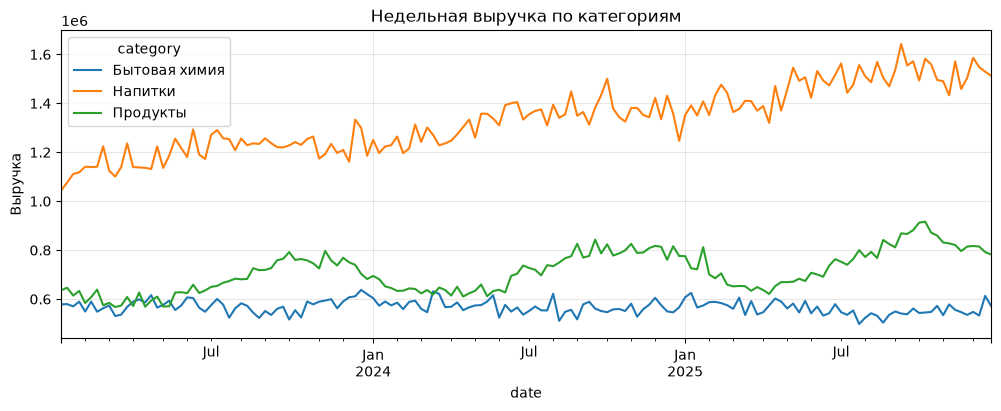

In [5]:
weekly.plot(figsize=(12, 4), title="Недельная выручка по категориям")
plt.ylabel("Выручка"); plt.grid(alpha=.3); plt.show()

In [6]:
train = weekly.iloc[:-TEST_WEEKS]
test = weekly.iloc[-TEST_WEEKS:]
print("train:", train.index.min().date(), "→", train.index.max().date(), len(train))
print("test: ", test.index.min().date(), "→", test.index.max().date(), len(test))

train: 2023-01-08 → 2025-11-02 148
test:  2025-11-09 → 2025-12-28 8


In [7]:
SEASON = 52
if len(train) < SEASON:
    SEASON = 4  # если данных мало — аналогичная неделя прошлого месяца

seasonal_naive = weekly.shift(SEASON).iloc[-TEST_WEEKS:]

# Линейный тренд
x_train = np.arange(len(train))
x_test = np.arange(len(train), len(train) + TEST_WEEKS)
trend = pd.DataFrame(index=test.index, columns=weekly.columns, dtype=float)
for cat in weekly.columns:
    k, b = np.polyfit(x_train, train[cat].values, deg=1)
    trend[cat] = k * x_test + b

forecasts = {"Сезонный наивный": seasonal_naive, "Линейный тренд": trend}

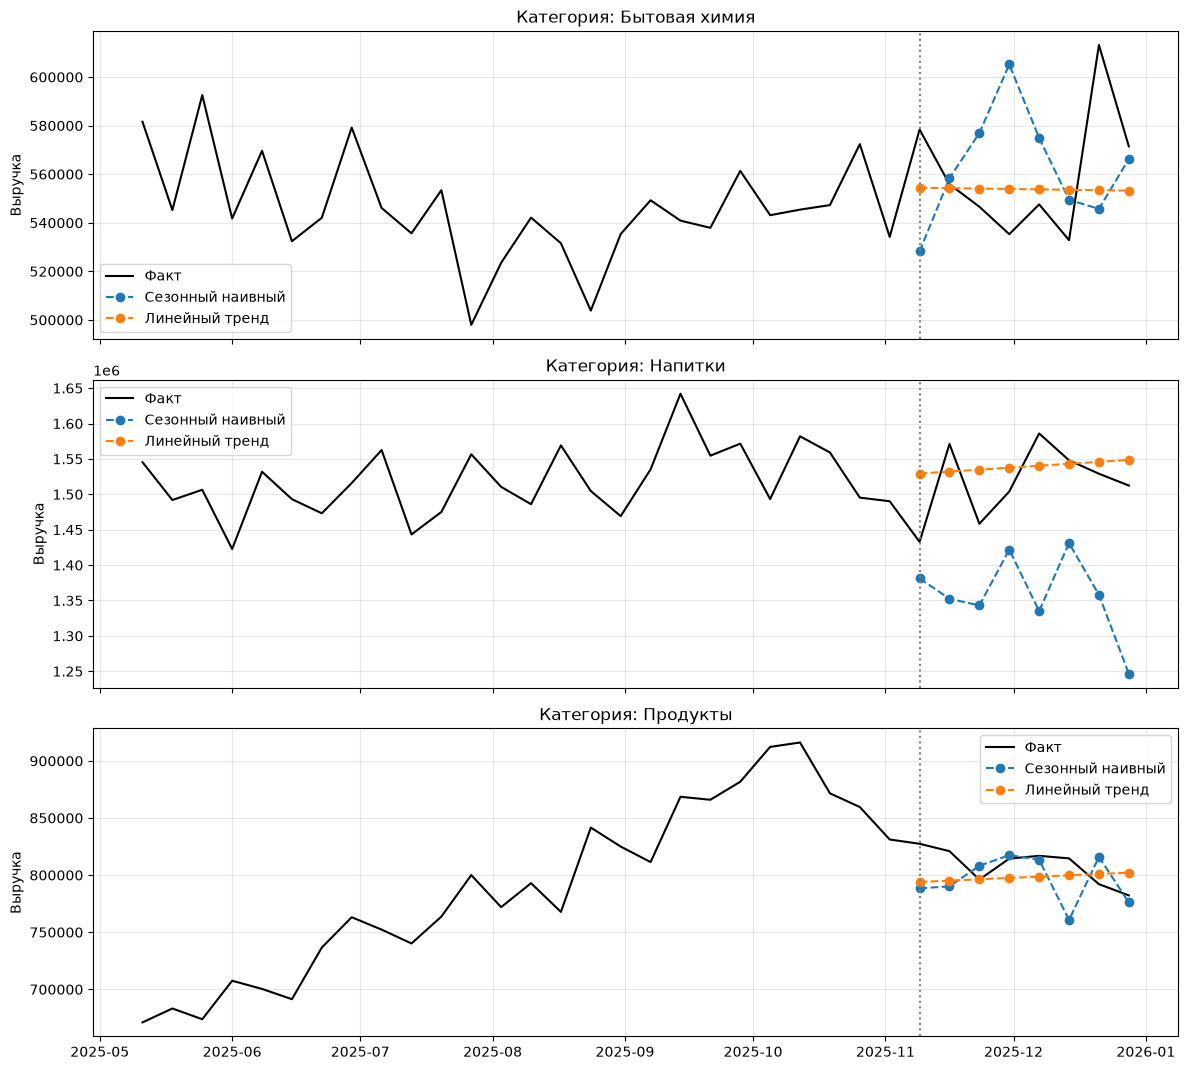

In [8]:
cats = list(weekly.columns)
fig, axes = plt.subplots(len(cats), 1, figsize=(12, 3.6 * len(cats)), sharex=True)
axes = np.atleast_1d(axes)
for ax, cat in zip(axes, cats):
    hist = weekly[cat].iloc[-(TEST_WEEKS + 26):]
    ax.plot(hist.index, hist.values, color="black", label="Факт")
    for name, f in forecasts.items():
        ax.plot(f.index, f[cat], marker="o", ls="--", label=name)
    ax.axvline(test.index[0], color="gray", ls=":")
    ax.set_title(f"Категория: {cat}")
    ax.set_ylabel("Выручка"); ax.grid(alpha=.3); ax.legend()
plt.tight_layout()
plt.show()

In [9]:
def mae(actual, pred):
    return np.mean(np.abs(actual - pred))

def mape(actual, pred):
    return np.mean(np.abs((actual - pred) / actual)) * 100

rows = []
for name, f in forecasts.items():
    for cat in cats:
        rows.append({"Метод": name, "Категория": cat,
                     "MAE": mae(test[cat].values, f[cat].values),
                     "MAPE, %": mape(test[cat].values, f[cat].values)})
metrics = pd.DataFrame(rows)
display(metrics.round(2))

summary = metrics.groupby("Метод")[["MAE", "MAPE, %"]].mean().round(2)
display(summary)

,Метод,Категория,MAE,"MAPE, %"
0,Сезонный наивный,Бытовая химия,33697.11,5.97
1,Сезонный наивный,Напитки,159067.32,10.38
2,Сезонный наивный,Продукты,21535.56,2.65
3,Линейный тренд,Бытовая химия,19571.81,3.40
4,Линейный тренд,Напитки,43659.01,2.92
5,Линейный тренд,Продукты,17284.45,2.13


,MAE,"MAPE, %"
Метод,,
Линейный тренд,26838.42,2.82
Сезонный наивный,71433.33,6.33


In [10]:
best = metrics.loc[metrics.groupby("Категория")["MAPE, %"].idxmin(), ["Категория", "Метод", "MAPE, %"]]
best.round(2)

,Категория,Метод,"MAPE, %"
3,Бытовая химия,Линейный тренд,3.40
4,Напитки,Линейный тренд,2.92
5,Продукты,Линейный тренд,2.13
